In [1]:
%load_ext autoreload
%autoreload 2
import slmpy #for controlling the slm
import time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse, Rectangle
# Local imports

from mpl_toolkits.axes_grid1.inset_locator import mark_inset
import matplotlib

from functions import cpx_corr
from fields import laguerre_gauss, hermite_gauss, speckle_gauss
from fourier_filter import fourier_filter

# from plotting.plot_funs import colorize
# from plotting.specialized_functions import plot_four

from phase_holograms import hologram_type1, hologram_type2, hologram_type3
import tkinter as tk
from PIL import Image, ImageTk
import scipy as sp
from scipy.special import j1

SMALL_SIZE = 14
MEDIUM_SIZE = 16
BIGGER_SIZE = 18

plt.rc('font', size=SMALL_SIZE)          # controls default text sizes
plt.rc('axes', titlesize=SMALL_SIZE)     # fontsize of the axes title
plt.rc('axes', labelsize=MEDIUM_SIZE)    # fontsize of the x and y labels
plt.rc('xtick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('ytick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('legend', fontsize=SMALL_SIZE)    # legend fontsize
plt.rc('figure', titlesize=MEDIUM_SIZE)  # fontsize of the figure title
matplotlib.rc('font', family='sans-serif') 
matplotlib.rc('font', serif='Helvetica') 

plt.rcParams.update({"figure.facecolor" : "white"})

slm = slmpy.SLMdisplay()
resX, resY = slm.getSize()

ModuleNotFoundError: No module named 'slmpy'

Here we define our target field

In [14]:
nx = 1280 ; ny = 1024 
X,Y = np.meshgrid(np.arange(nx)-nx/2,np.arange(ny)-ny/2)

Nt = 4 # Total order of LG beam
ell = 2 # topologicla charge
hlg_sc= 3*np.sqrt(Nt+1)/ny # Size of LG beam scales as Nt^(1/2)
field = laguerre_gauss(Nt, ell, hlg_sc*X, hlg_sc*Y)
# field = hermite_gauss(Nt, ell, hlg_sc*X, hlg_sc*Y)
field /= np.max(np.abs(field)) # set maximum amplitude value to one
# field=np.ones((nx,ny))*np.exp(1j*np.pi/4)

In [15]:
plt.imshow(colorize(field))
plt.gca().axis('off')

NameError: name 'colorize' is not defined

Now we compute the phase hologram and simulate its passage through the 4f system

NameError: name 'plot_four' is not defined

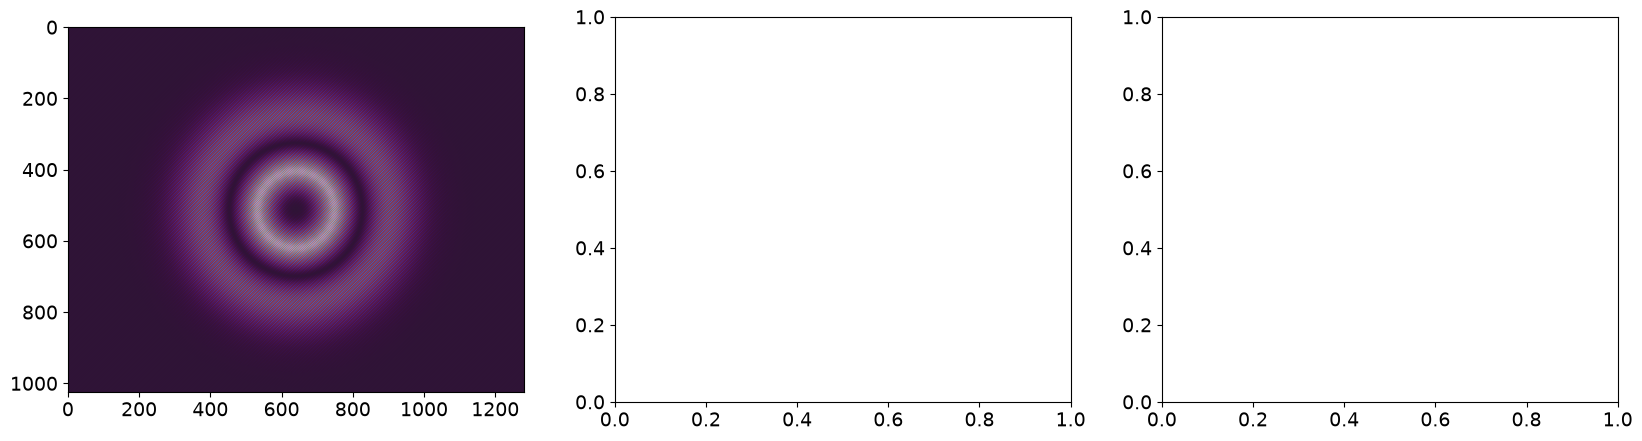

In [ ]:
nuvec = 0.1*np.array([1.,1.])#np.array([1/3,1/3])
SA_filter = 1/25
holo = hologram_type3(field, nuvec, fa=None)
shaped_f, ft_holo = fourier_filter(np.exp(1j*(holo)), -nuvec, SA_filter , get_ft=True)

fig, axs = plt.subplots(1,3, figsize=(20,5))

axs[0].imshow(holo, cmap='twilight', interpolation=None)#,vmin=-np.pi/2,vmax=np.pi/2)
# plt.colorbar()
# plot_four(ft_holo, ax=axs[1],  log=True, ap_rad= SA_filter, 
        #   ap_loc=-nuvec, vmin=-8, vmax=10.)

axs[2].imshow(colorize(shaped_f))

for i, ax in enumerate(axs.ravel()):
    ax.axis('off')


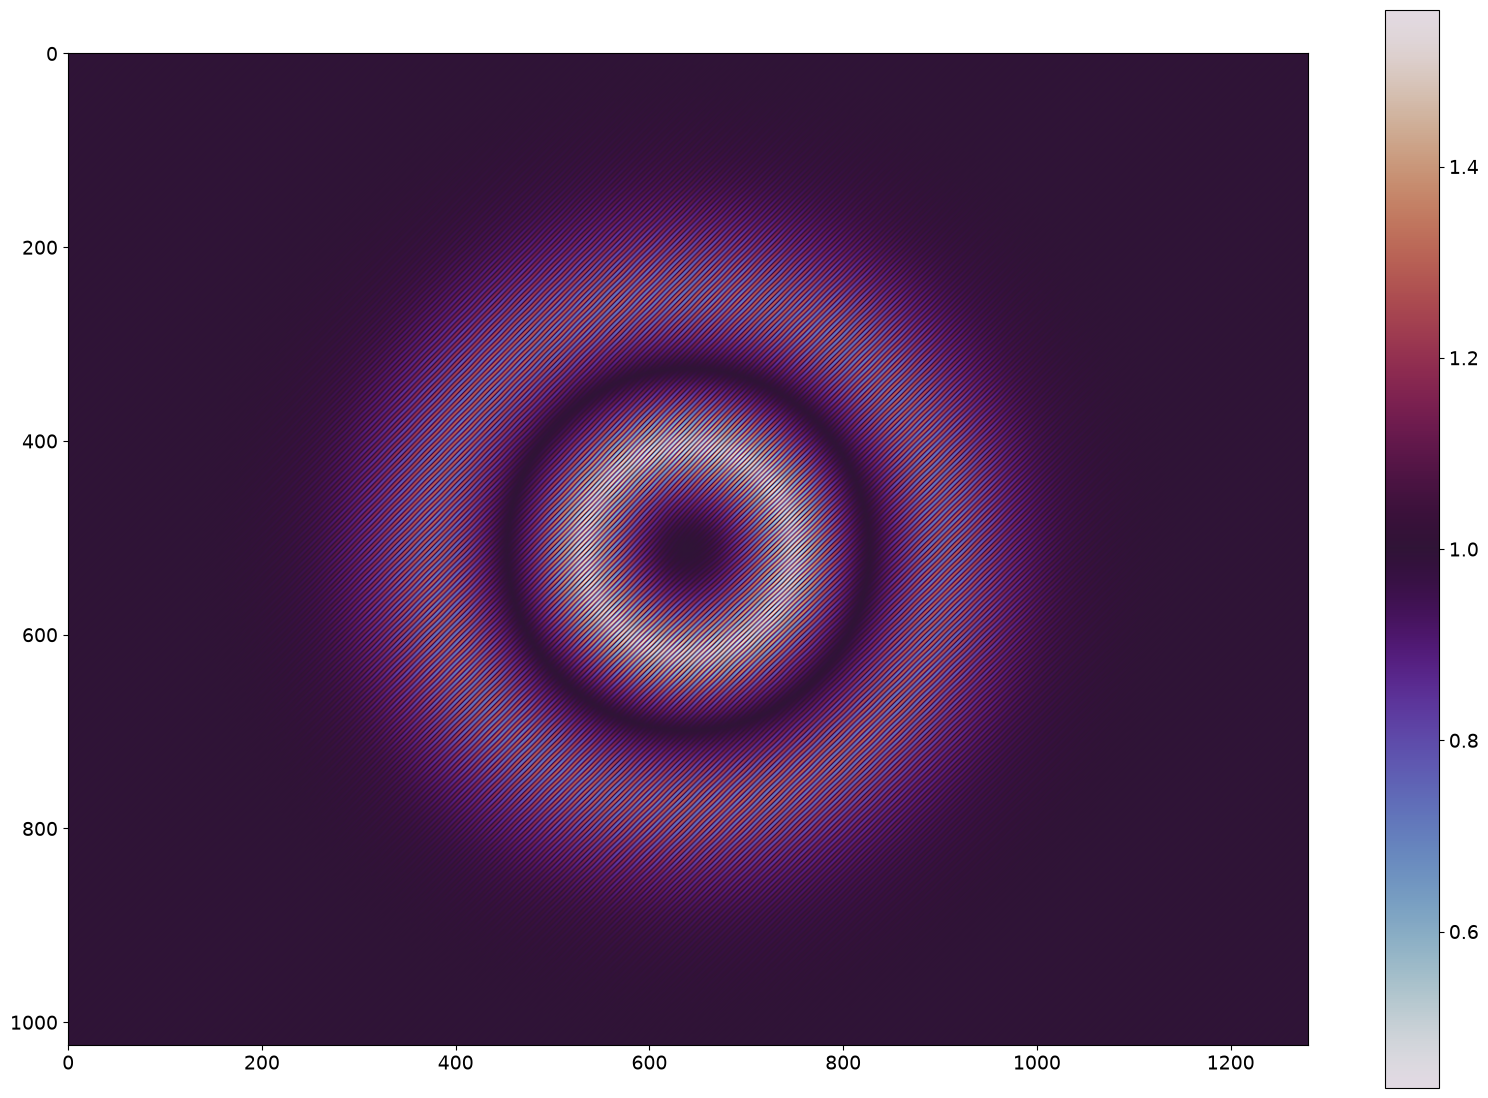

In [17]:
holo = hologram_type3(field, nuvec, fa=None)
fig = plt.figure(figsize=(20,14))
plt.imshow(holo/np.pi, cmap='twilight', interpolation=None)
plt.colorbar()

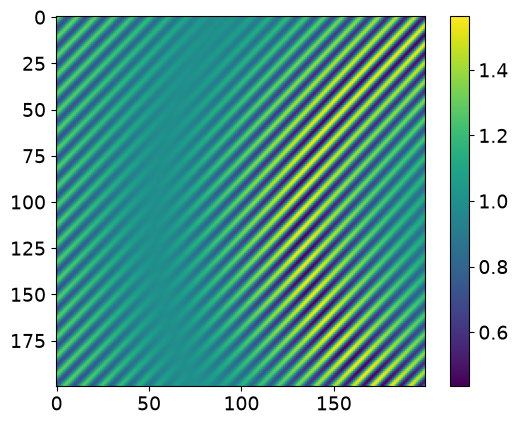

In [18]:
plt.imshow(holo[400:600,400:600]/np.pi)
plt.colorbar()

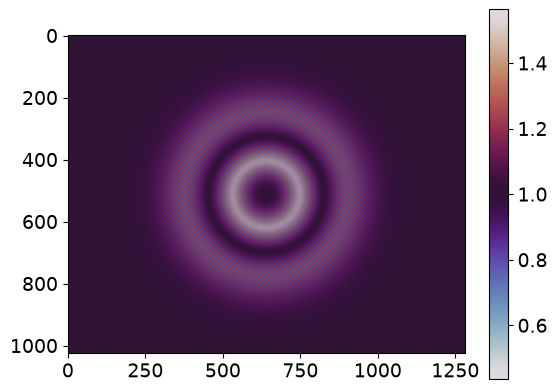

In [19]:
plt.imshow(holo/np.pi, cmap='twilight', interpolation=None)
plt.colorbar()

In [ ]:
image = np.asarray(holo)

print("Image shape:", image.shape)
print("Image dtype:", image.dtype)
print("Image range:", image.min(), image.max())

# Ensure an 8-bit grayscale image
image = np.clip(image, 0, 224).astype(np.uint8) #maximum for Hamamatsu for a 2pi modulation
pil_image = Image.fromarray(image)

# Create display window
root = tk.Tk()
root.overrideredirect(True)
root.attributes("-topmost", True)

height, width = image.shape[:2]

# SLM monitor position
x, y = 1920, 0
root.geometry(f"{width}x{height}+{x}+{y}")

photo = ImageTk.PhotoImage(pil_image)
label = tk.Label(root, image=photo, borderwidth=0, highlightthickness=0)
label.pack()

root.bind("<Escape>", lambda event: root.destroy())

print("Window geometry:", root.geometry())
root.mainloop()

Image shape: (1024, 1280)
Image dtype: float64
Image range: 1.370959474902854 4.912519787426927
Window geometry: 1x1+1920+0
